# 01 · 数据探索与数据契约（Phase 1）

对 Retailrocket 电商行为数据集做**全量流式**探索（本地 CSV，无数据库）：

| 文件 | 行数 | 内容 |
| --- | --- | --- |
| `events.csv` | 2,756,101 | 行为事件（view / addtocart / transaction） |
| `item_properties_part1/2.csv` | 10,999,999 + 9,275,903 | 商品属性（时间变化快照） |
| `category_tree.csv` | 1,669 | 类目树 |

统计逻辑全部在 `src/ecommerce_dw/eda`，notebook 只负责调用与出图。
口径定义见 `docs/{data_dictionary,metric_definitions,data_contract}.md`。

> 本 notebook 已用 `jupyter nbconvert --execute` 实际执行过，输出留存；
> Restart & Run All 可完整复现（全量跑到 item_properties 约 2 分钟）。


In [1]:
# 【环境与路径】支持在仓库任意子目录启动
import sys
from datetime import UTC, datetime
from pathlib import Path

import matplotlib.pyplot as plt

# 让图表正确渲染中文（Windows 内置微软雅黑；不配置则 CJK 字形显示为方块）
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

PROJECT_ROOT = Path.cwd()
while not (PROJECT_ROOT / ".git").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    raise SystemExit("未找到仓库根目录（含 src/），请在本仓库内启动 Jupyter")

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ecommerce_dw.eda import (  # noqa: E402
    category_depth_distribution,
    daily_event_counts,
    scan_csv,
    summarize_category_tree,
    summarize_events,
    summarize_item_properties,
)

DATA_DIR = PROJECT_ROOT / "data" / "raw" / "retailrocket"
EVENTS = DATA_DIR / "events.csv"
PROPERTIES = [DATA_DIR / "item_properties_part1.csv", DATA_DIR / "item_properties_part2.csv"]
CATEGORY_TREE = DATA_DIR / "category_tree.csv"
if not (EVENTS.exists() and CATEGORY_TREE.exists()):
    raise SystemExit("原始数据缺失，请先按 docs/dataset.md 下载 data/raw/retailrocket/")


def utc(ms: int) -> str:
    return datetime.fromtimestamp(int(ms) / 1000, tz=UTC).strftime("%Y-%m-%d %H:%M:%S UTC")


print("PROJECT_ROOT =", PROJECT_ROOT)
print("DATA_DIR     =", DATA_DIR)


PROJECT_ROOT = C:\Zproject\data-engineering\ecommerce-data-platform
DATA_DIR     = C:\Zproject\data-engineering\ecommerce-data-platform\data\raw\retailrocket


In [2]:
# ① 通用流式扫描 events.csv：逐字段画像 + 行级重复
import time as _t

_t0 = _t.time()
ev_scan = scan_csv(EVENTS)
_t1 = _t.time()
print(f"[scan_csv 耗时 {_t1 - _t0:.1f}s]")
print(
    f"行数={ev_scan.n_rows:,}  行级完全重复={ev_scan.n_duplicate_rows:,} 行"
    f"（源自 {ev_scan.n_duplicate_groups:,} 个不同重复行内容）  畸形行={ev_scan.n_malformed_rows}"
)
print()
print(f"{'字段':<14}{'推断类型':<9}{'缺失':>11}{'非空':>13}{'去重非空':>13}")
for c in ev_scan.columns:
    print(f"{c.name:<14}{c.inferred_type:<9}{c.n_missing:>11,}{c.n_nonempty:>13,}{c.distinct_nonempty:>13,}")


[scan_csv 耗时 20.3s]
行数=2,756,101  行级完全重复=460 行（源自 458 个不同重复行内容）  畸形行=0

字段            推断类型              缺失           非空         去重非空
timestamp     int                0    2,756,101    2,750,455
visitorid     int                0    2,756,101    1,407,580
event         str                0    2,756,101            3
itemid        int                0    2,756,101      235,061
transactionid int        2,733,644       22,457       17,672


#### scan_csv 结论
- 5 列均无空值；`timestamp` / `visitorid` / `itemid` / `transactionid` 推断为整型，
  `event` 为字符串（白名单 3 值）。
- `transactionid` 只在交易事件上非空：2,733,644 行缺失，非空 22,457 行、去重 17,672 个。
- 行级完全重复 **460 行**（0.017%），由 458 个不同行内容重复而来 → ODS 原样保留、DWD 按业务键去重。
- 时间戳非单调：线性顺序下 **1,377,377** 行的时间戳小于前一行，文件乱序，增量处理不能依赖文件位置。


In [3]:
# ② events 专项统计：类型 / 时间 / 覆盖 / transactionid
_t0 = _t.time()
ev = summarize_events(EVENTS)
_t1 = _t.time()
print(f"[summarize_events 耗时 {_t1 - _t0:.1f}s]")
print(f"总行数              {ev.n_rows:,}")
for k, v in ev.event_counts.items():
    print(f"  event={k:<12}{v:>12,}  占比 {v / ev.n_rows * 100:.2f}%")
print(f"未知事件类型        {ev.unknown_events or '无'}")
print(f"时间范围            {utc(ev.ts_min_ms)}  ~  {utc(ev.ts_max_ms)}")
print(f"非法/缺失时间戳     {ev.n_invalid_ts}")
print(
    f"去重 visitorid      {ev.n_visitors:,}"
    f"（visitorid='0' 哨兵 {ev.n_visitor_zero} 行 / 缺失 {ev.n_missing_visitor} 行）"
)
print(f"去重 itemid         {ev.n_items:,}（缺失 {ev.n_missing_item} 行）")
print(
    f"transaction 事件    {ev.n_transaction_rows:,} 行，"
    f"缺 transactionid {ev.transaction_rows_missing_txnid} 行"
)
print(f"非交易行却带 txnid   {ev.txnid_non_transaction_rows} 行")
print(
    f"去重 transactionid  {ev.n_transactionids:,}"
    f"（{ev.n_txnid_reused:,} 个 txnid 跨多笔交易，单 id 最多 {ev.max_txnid_events} 行）"
)


[summarize_events 耗时 2.3s]
总行数              2,756,101
  event=view           2,664,312  占比 96.67%
  event=addtocart         69,332  占比 2.52%
  event=transaction       22,457  占比 0.81%
未知事件类型        无
时间范围            2015-05-03 03:00:04 UTC  ~  2015-09-18 02:59:47 UTC
非法/缺失时间戳     0
去重 visitorid      1,407,580（visitorid='0' 哨兵 3 行 / 缺失 0 行）
去重 itemid         235,061（缺失 0 行）
transaction 事件    22,457 行，缺 transactionid 0 行
非交易行却带 txnid   0 行
去重 transactionid  17,672（2,710 个 txnid 跨多笔交易，单 id 最多 31 行）


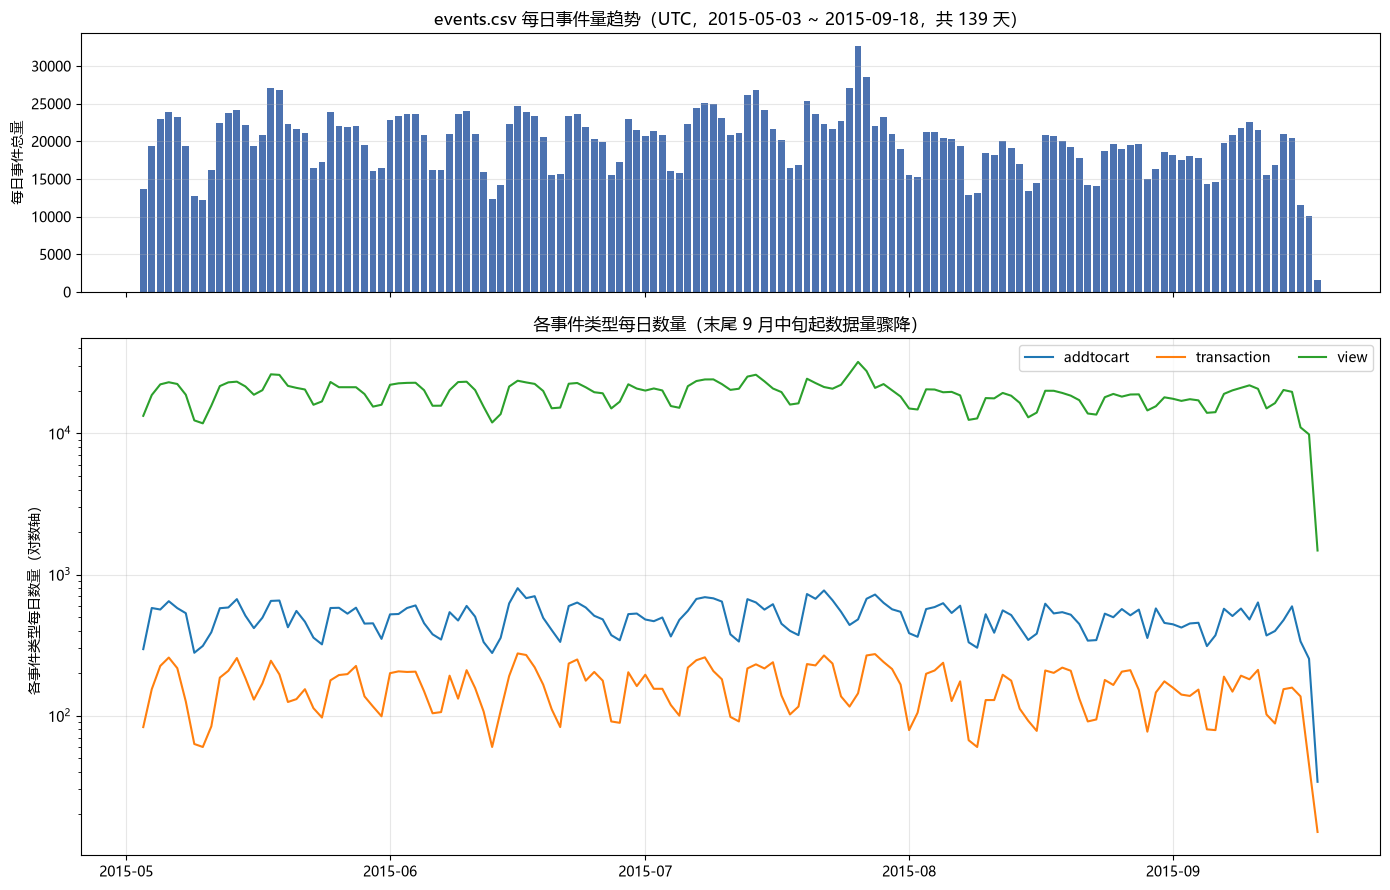

最低的 5 天: [('2015-09-18', 1528), ('2015-09-17', 10128), ('2015-09-16', 11495), ('2015-05-10', 12143), ('2015-06-13', 12270)]
最高的 3 天: [('2015-07-26', 32703), ('2015-07-27', 28562), ('2015-07-25', 27106)]


In [4]:
# ③ 每日事件量趋势（UTC），两联图：总量 + 按事件类型（对数轴）
import matplotlib.dates as mdates

daily = daily_event_counts(EVENTS)
dates = [datetime.strptime(d, "%Y-%m-%d") for d in daily.dates]
total = [sum(daily.counts_by_event[e][i] for e in daily.counts_by_event) for i in range(len(dates))]

fig, (ax0, ax1) = plt.subplots(
    2, 1, figsize=(14, 9), sharex=True, gridspec_kw={"height_ratios": [1, 2]}
)
ax0.bar(dates, total, color="#4C72B0")
ax0.set_ylabel("每日事件总量")
ax0.set_title("events.csv 每日事件量趋势（UTC，2015-05-03 ~ 2015-09-18，共 139 天）")
ax0.grid(axis="y", alpha=0.3)

for event in sorted(daily.counts_by_event):
    ax1.plot(dates, daily.counts_by_event[event], label=event, linewidth=1.5)
ax1.set_yscale("log")
ax1.set_ylabel("各事件类型每日数量（对数轴）")
ax1.set_title("各事件类型每日数量（末尾 9 月中旬起数据量骤降）")
ax1.legend(ncol=3)
ax1.grid(alpha=0.3)
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.tight_layout()
plt.show()

total_by_day = dict(zip(daily.dates, total, strict=True))
print("最低的 5 天:", sorted(total_by_day.items(), key=lambda kv: kv[1])[:5])
print("最高的 3 天:", sorted(total_by_day.items(), key=lambda kv: kv[1], reverse=True)[:3])


#### 每日序列观察
- 覆盖 **139 个 UTC 日**；谷底集中在 **2015-09-16 ~ 09-18**（末段 11,495 / 10,128 / 1,528
  事件），数据采集在 9 月中旬陡降，**尾段窗口不完整**，DAU/留存类指标须整日排除
  （见 `metric_definitions.md` §3 / §8）。
- 峰值 7 月下旬（最高 07-26 的 32,703 事件）。
- 2015-05-10 当天总量偏低（12,143），恰为 item_properties 快照的起点日，
  不排除采集链路调整所致，暂不深究。


In [5]:
# ④ item_properties 两张 part 合并统计（单遍流式扫 20.3M 行）
_t0 = _t.time()
prop = summarize_item_properties(PROPERTIES)
_t1 = _t.time()
print(f"[summarize_item_properties 耗时 {_t1 - _t0:.1f}s]")
print(f"总行数              {prop.n_rows:,}（{prop.n_files} 个文件）")
print(
    f"时间范围            {utc(prop.ts_min_ms)}  ~  {utc(prop.ts_max_ms)}"
    f"（非法时间戳 {prop.n_invalid_ts}）"
)
print(f"去重商品 itemid     {prop.n_items:,}")
print(f"去重属性名 property {prop.n_properties:,}")
print(f"去重值 value        {prop.n_distinct_values:,}")
print(f"行级完全重复        {prop.n_duplicate_rows:,}（重复组 {prop.n_duplicate_groups:,}）")
print(f"缺失字段            {prop.n_missing or '无'}")
print(f"categoryid 属性取值 {len(prop.categoryid_values):,} 个")
print()
print(f"{'属性名':<14}{'记录数':>13}{'占总行%':>10}")
for name, n in list(prop.property_counts.items())[:10]:
    print(f"{name:<14}{n:>13,}{n / prop.n_rows * 100:>9.2f}%")


[summarize_item_properties 耗时 84.3s]
总行数              20,275,902（2 个文件）
时间范围            2015-05-10 03:00:00 UTC  ~  2015-09-13 03:00:00 UTC（非法时间戳 0）
去重商品 itemid     417,053
去重属性名 property 1,104
去重值 value        1,966,868
行级完全重复        0（重复组 0）
缺失字段            无
categoryid 属性取值 1,242 个

属性名                     记录数      占总行%
888               3,000,398    14.80%
790               1,790,516     8.83%
available         1,503,639     7.42%
categoryid          788,214     3.89%
6                   631,471     3.11%
283                 597,419     2.95%
776                 574,220     2.83%
678                 481,966     2.38%
364                 476,486     2.35%
202                 448,938     2.21%


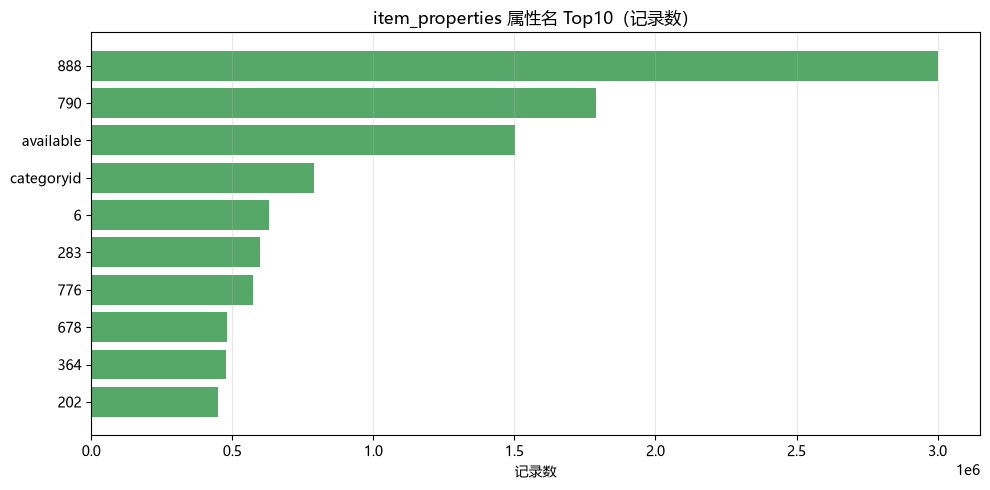

In [6]:
# ⑤ 属性名 Top10 条形图：可读属性与数字编码并存
top = list(prop.property_counts.items())[:10]
names = [n for n, _ in top][::-1]
counts = [c for _, c in top][::-1]
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(names, counts, color="#55A868")
ax.set_title("item_properties 属性名 Top10（记录数）")
ax.set_xlabel("记录数")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:
# ⑥ 跨表引用检查：事件商品 ↔ 属性覆盖，类目属性 ↔ 类目树
import csv as _csv

events_items = ev.item_ids
covered = events_items & prop.items
print(f"事件引用的商品数       {len(events_items):,}")
print(
    f"其中有属性记录的商品   {len(covered):,}"
    f"（{len(covered) / len(events_items) * 100:.2f}%）"
)
no_props = events_items - covered
print(
    f"完全无属性记录的商品   {len(no_props):,}"
    f"（{len(no_props) / len(events_items) * 100:.2f}%）"
)

cat_vals = prop.categoryid_values
with open(CATEGORY_TREE, newline="", encoding="utf-8") as fh:
    r = _csv.reader(fh)
    next(r)
    cat_ids = {row[0] for row in r}
in_tree = cat_vals & cat_ids
out_of_tree = cat_vals - cat_ids
print()
print(f"categoryid 属性取值数  {len(cat_vals):,}")
print(f"其中在类目树中         {len(in_tree):,}（{len(in_tree) / len(cat_vals) * 100:.1f}%）")
print(f"其中越界(不在树中)     {len(out_of_tree):,}，例如 {sorted(out_of_tree)[:6]}")
print(f"类目树从未被引用       {len(cat_ids - cat_vals):,} / {len(cat_ids):,}")


事件引用的商品数       235,061
其中有属性记录的商品   185,246（78.81%）
完全无属性记录的商品   49,815（21.19%）

categoryid 属性取值数  1,242
其中在类目树中         1,212（97.6%）
其中越界(不在树中)     30，例如 ['1046', '1062', '1123', '1158', '1319', '1428']
类目树从未被引用       457 / 1,669


#### 跨表结论
- 事件引用的 235,061 件商品中 **78.81%** 有属性记录，**21.19%（49,815）无任何属性**；
  属性表共 417,053 件商品，目录大于被浏览集合。
- `categoryid` 属性值 97.6% 落在类目树内；**30 个越界值**（如 `1046`、`1123`）属于数据漂移。


节点 1,669（重复定义 0）  根节点 25  边 1,644
孤儿引用 无  孤儿节点 0  环 0  不可达 0
最大深度 5


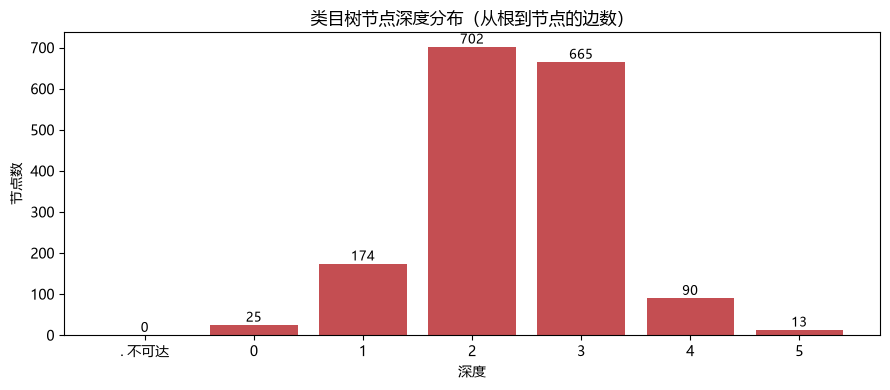

In [8]:
# ⑦ 类目树结构：规模 / 根 / 深度分布 / 孤儿
tree = summarize_category_tree(CATEGORY_TREE)
print(
    f"节点 {tree.n_nodes:,}（重复定义 {tree.n_duplicate_nodes:,}）  "
    f"根节点 {tree.root_count:,}  边 {tree.n_edges:,}"
)
print(
    f"孤儿引用 {tree.orphan_references or '无'}  孤儿节点 {tree.n_orphan_parent_nodes:,}"
    f"  环 {tree.n_cycle_nodes:,}  不可达 {tree.n_unreachable_nodes:,}"
)
print(f"最大深度 {tree.max_depth}")

dist = category_depth_distribution(CATEGORY_TREE)
fig, ax = plt.subplots(figsize=(9, 4))
labels = [". 不可达" if d == -1 else str(d) for d in sorted(dist)]
ax.bar(labels, [dist[d] for d in sorted(dist)], color="#C44E52")
ax.set_title("类目树节点深度分布（从根到节点的边数）")
ax.set_xlabel("深度")
ax.set_ylabel("节点数")
for i, d in enumerate(sorted(dist)):
    ax.text(i, dist[d], f"{dist[d]:,}", ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()


## 关键发现小结

| 主题 | 实测结论 |
| --- | --- |
| 事件规模 | 2,756,101 行：view 2,664,312（96.7%）/ addtocart 69,332 / transaction 22,457；无未知类型 |
| 访客 / 商品 | 去重访客 1,407,580（含 3 个 `visitorid='0'` 哨兵）；去重商品 235,061 |
| 成交标识 | transactionid 为**订单级**：17,672 去重 ID 对应 22,457 笔交易事件（2,710 个 ID 复用）；行数 ≠ 订单数 |
| 商品属性 | 20,275,902 行、417,053 商品、1,104 种属性名（多数为数字编码）；无缺失、无完全重复行 |
| 类目树 | 1,669 节点 / 25 根 / 最大深度 5 / 无孤儿 / 无环（良构森林） |
| 时间 | 事件 139 个 UTC 日（05-03 ~ 09-18）；属性按日快照（05-10 ~ 09-13，刻度 03:00 UTC）；**文件乱序** |
| 交叉 | 事件商品 78.8% 有属性；categoryid 属性值 30 个越界类目树 |

详细字段说明、指标口径与异常处置见：
- `docs/data_dictionary.md`
- `docs/metric_definitions.md`
- `docs/data_contract.md`
